# Analista bayesiana: versión sencilla

Un archivo principal, seis factores y una tabla de Euler. Probabilidades didácticas, no calibración clínica. Ejecutar de arriba abajo.

In [1]:
from pathlib import Path
import sys, csv
raiz=Path.cwd()
if not (raiz/"src").is_dir(): raiz=raiz.parent
sys.path.insert(0,str(raiz))
import numpy as np
import matplotlib.pyplot as plt
from src.bayes_net import configuracion, construir, consulta, FACTORES
cfg=configuracion()
tabla=construir()
print("Combinaciones:",len(tabla))
for f in FACTORES: print(f,cfg["bayes"]["niveles"][f])

Combinaciones: 64
Concentracion [1.0, 5.0]
Duracion [10.0, 20.0]
Frecuencia [0.5, 1.0]
TolerPrevia [0.0001, 0.01]
TasaMutacion ['nominal', 'metabolico']
CosteFitness [0.0, 0.2]


## 1. DAG
Seis factores apuntan a la adquisición de resistencia. Los factores son independientes por supuesto del diseño.

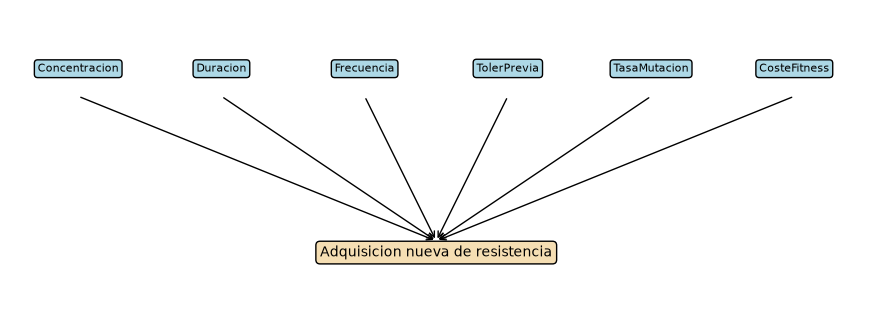

In [2]:
fig,ax=plt.subplots(figsize=(11,4))
ax.set(xlim=(0,1),ylim=(0,1)); ax.axis("off")
for i,f in enumerate(FACTORES):
    x=.08+.168*i
    ax.annotate("",xy=(.5,.25),xytext=(x,.72),arrowprops=dict(arrowstyle="->"))
    ax.text(x,.8,f,ha="center",fontsize=8,bbox=dict(boxstyle="round",fc="lightblue"))
ax.text(.5,.2,"Adquisicion nueva de resistencia",ha="center",bbox=dict(boxstyle="round",fc="wheat"))
plt.show()

## 2. CPT
Cada fila usa Euler y P(evento)=1-exp(-eventos esperados). P(ninguna transición)=1-P(transición). No son observaciones de laboratorio.

In [3]:
for fila in tabla[:4]: print(fila)
print("Primera fila: P(no nueva R)=",1-tabla[0]["ProbResistencia"])
carpeta=raiz/"data/bayes"; carpeta.mkdir(parents=True,exist_ok=True)
with (carpeta/"cpt_simuladas.csv").open("w",newline="",encoding="utf-8") as f:
    w=csv.DictWriter(f,fieldnames=list(tabla[0]))
    w.writeheader(); w.writerows(tabla)

{'Concentracion': 0, 'Duracion': 0, 'Frecuencia': 0, 'TolerPrevia': 0, 'TasaMutacion': 0, 'CosteFitness': 0, 'ProbTolerancia': 1.0, 'ProbResistencia': 0.005879546337148156}
{'Concentracion': 0, 'Duracion': 0, 'Frecuencia': 0, 'TolerPrevia': 0, 'TasaMutacion': 0, 'CosteFitness': 1, 'ProbTolerancia': 1.0, 'ProbResistencia': 0.005879551957992057}
{'Concentracion': 0, 'Duracion': 0, 'Frecuencia': 0, 'TolerPrevia': 0, 'TasaMutacion': 1, 'CosteFitness': 0, 'ProbTolerancia': 1.0, 'ProbResistencia': 0.005000367355430635}
{'Concentracion': 0, 'Duracion': 0, 'Frecuencia': 0, 'TolerPrevia': 0, 'TasaMutacion': 1, 'CosteFitness': 1, 'ProbTolerancia': 1.0, 'ProbResistencia': 0.005000372235697159}
Primera fila: P(no nueva R)= 0.9941204536628518


## 3. Consulta del documento y cálculo manual
Tres horas diarias, diez días, concentración alta y tolerancia previa baja. Perfil y coste desconocidos dejan cuatro filas equiprobables.

In [4]:
e=dict(Concentracion=1,Duracion=0,Frecuencia=1,TolerPrevia=0)
compatibles=[r for r in tabla if all(r[k]==v for k,v in e.items())]
for fila in compatibles: print(fila)
manual=sum(r["ProbResistencia"] for r in compatibles)/len(compatibles)
print("Manual:",manual,"consulta():",consulta(e,tabla))
assert np.isclose(manual,consulta(e,tabla))
print("Nueva tolerancia:",consulta(e,tabla,variable="ProbTolerancia"))

{'Concentracion': 1, 'Duracion': 0, 'Frecuencia': 1, 'TolerPrevia': 0, 'TasaMutacion': 0, 'CosteFitness': 0, 'ProbTolerancia': 0.7456941931460346, 'ProbResistencia': 0.007054509570266987}
{'Concentracion': 1, 'Duracion': 0, 'Frecuencia': 1, 'TolerPrevia': 0, 'TasaMutacion': 0, 'CosteFitness': 1, 'ProbTolerancia': 0.7456980695131166, 'ProbResistencia': 0.007056364776112156}
{'Concentracion': 1, 'Duracion': 0, 'Frecuencia': 1, 'TolerPrevia': 0, 'TasaMutacion': 1, 'CosteFitness': 0, 'ProbTolerancia': 0.999998823195011, 'ProbResistencia': 0.003172395754974189}
{'Concentracion': 1, 'Duracion': 0, 'Frecuencia': 1, 'TolerPrevia': 0, 'TasaMutacion': 1, 'CosteFitness': 1, 'ProbTolerancia': 0.9999988233682744, 'ProbResistencia': 0.003173214168598837}
Manual: 0.005114121067488042 consulta(): 0.005114121067488042
Nueva tolerancia: 0.8728474773056092


## 4. Cambiar un factor a la vez
Se mantiene una base completa; duración, tolerancia inicial y perfil se cambian por separado.

Base 0.007056364776112156
T previa alta 0.30772803154734285
20 dias 0.6971509796505794
Perfil C 0.003173214168598837


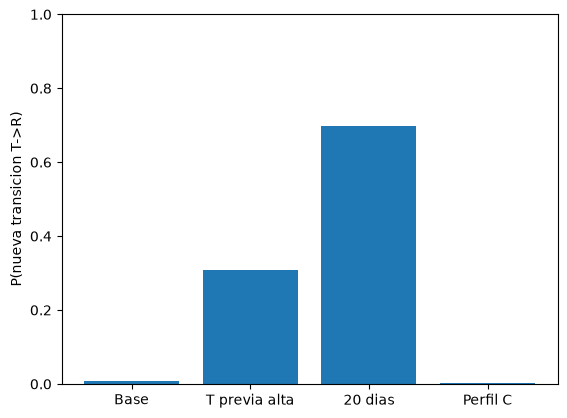

In [5]:
base=dict(e,TasaMutacion=0,CosteFitness=1)
casos={"Base":base,"T previa alta":dict(base,TolerPrevia=1),"20 dias":dict(base,Duracion=1),"Perfil C":dict(base,TasaMutacion=1)}
valores=[consulta(ev,tabla) for ev in casos.values()]
for nombre,valor in zip(casos,valores): print(nombre,valor)
plt.bar(casos.keys(),valores)
plt.ylabel("P(nueva transicion T->R)"); plt.ylim(0,1); plt.show()

## 5. Pipeline
Las tasas del perfil se comparten con Euler y EKF. No se convierte P(resistencia) en muTR.

{'escenario': 'B', 'dias': 20, 'origen': 'simulacion didactica, no calibracion experimental', 'tasas': {'muST': 0.0001, 'muTR': 1e-05}, 'probabilidades': {'ProbTolerancia': 0.7524109646717494, 'ProbResistencia': 0.6971372361281609}, 'metricas': {'fraccion_R_final': 0.1356019875698651, 't_dominancia_R_dias': None, 't_extincion_S_dias': None}, 'fraccion_R_EKF': 0.13747543743477958, 'RMSE': [39800.42267445415, 683996.1029405112, 50204.242736017535]}


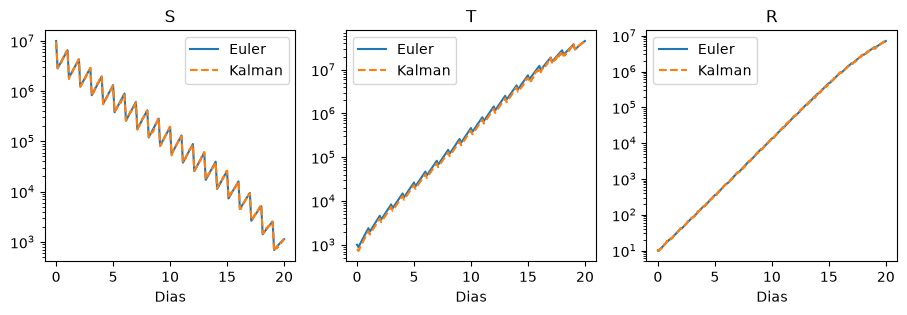

In [6]:
from src.pipeline import ejecutar_pipeline,guardar
r=ejecutar_pipeline("B"); guardar(r)
print(r["resumen"])
fig,axes=plt.subplots(1,3,figsize=(11,3))
for j,ax in enumerate(axes):
    ax.semilogy(r["t"],r["X"][:,j],label="Euler")
    ax.semilogy(r["t"],r["estimados"][:,j],"--",label="Kalman")
    ax.set(title=("S","T","R")[j],xlabel="Dias"); ax.legend()
plt.show()

## 6. Ejercicios cruzados
Se comparan dos pasos de Euler. En A se varían Q y R conservando mediciones. Interpretar y exponer los resultados es una actividad personal pendiente.

In [7]:
from src.euler_model import load_params,simulate,metricas
p,sc=load_params("B")
for paso in [sc["dt_horas"],sc["dt_horas"]/2]:
    t,X,C,dt=simulate("B",p,dict(sc,dt_horas=paso))
    print("Paso",paso,metricas(t,X))
from src.filtro_kalman import filtrar,rmse
a=ejecutar_pipeline("A")
x0=a["X"][0]*np.array(cfg["bayes"]["factor_inicial_kalman"])
P0=np.diag((cfg["bayes"]["sd_inicial_kalman"]*x0)**2)
qbase=cfg["scenarios"]["D"]["kalman"]["q_rel"]
for fq in cfg["bayes"]["factores_Q"]:
    for fr in cfg["bayes"]["factores_R"]:
        est,P=filtrar(a["t"],a["medidas"],fr*a["R_medicion"],a["H"],a["parametros"],a["C"],x0,P0,qbase*fq)
        print("Factor Q",fq,"factor R",fr,"RMSE T",rmse(a["X"],est)[1])

Paso 0.5 {'fraccion_R_final': 0.1356019875698651, 't_dominancia_R_dias': None, 't_extincion_S_dias': None}
Paso 0.25 {'fraccion_R_final': 0.12696721984020026, 't_dominancia_R_dias': None, 't_extincion_S_dias': None}
Factor Q 0.25 factor R 0.5 RMSE T 646.7364887506977
Factor Q 0.25 factor R 1.0 RMSE T 655.029639988636
Factor Q 0.25 factor R 2.0 RMSE T 660.8248213951994
Factor Q 1.0 factor R 0.5 RMSE T 643.124814891756
Factor Q 1.0 factor R 1.0 RMSE T 648.5948065704778
Factor Q 1.0 factor R 2.0 RMSE T 654.4095219717016


## Conclusión
Se condicionan y marginalizan factores desconocidos. Las CPT son del simulador y no tienen intervalos de parámetros ni calibración clínica. La fracción R final y la adquisición nueva son resultados diferentes. La revisión cruzada y la defensa oral se realizan con el equipo.